## 1. Import Libraries

In [1]:
import numpy as np

import pandas as pd

import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
	OneHotEncoder,
	OrdinalEncoder,
	StandardScaler,
	MinMaxScaler,
	PowerTransformer,
	FunctionTransformer
)

from feature_engine.outliers import Winsorizer
from feature_engine.datetime import DatetimeFeatures
from feature_engine.selection import SelectBySingleFeaturePerformance
from feature_engine.encoding import (
	RareLabelEncoder,
	MeanEncoder,
	CountFrequencyEncoder
)

import matplotlib.pyplot as plt

import warnings

## 2. Display Settings

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
sklearn.set_config(transform_output="pandas")

In [4]:
warnings.filterwarnings("ignore")

## 3. Read the Data

In [5]:
path = r"C:\flight_price prediction_AWS_sagemaker\Dataset\train.csv"

train = pd.read_csv(path)
train

,airline,date_of_journey,source,destination,dep_time,arrival_time,duration,total_stops,additional_info,price
0,Indigo,2019-04-27,Delhi,Cochin,16:00:00,21:00:00,300,1.0,No Info,6937
1,Vistara,2019-04-01,Kolkata,Banglore,07:10:00,23:25:00,975,1.0,No Info,7927
2,Jet Airways,2019-05-27,Delhi,Cochin,14:00:00,19:00:00,300,1.0,In-flight meal not included,12898
3,Jet Airways,2019-06-24,Delhi,Cochin,20:55:00,19:00:00,1325,1.0,In-flight meal not included,10262
4,Jet Airways,2019-05-18,Delhi,Cochin,14:00:00,19:00:00,300,1.0,In-flight meal not included,12373
...,...,...,...,...,...,...,...,...,...,...
635,Air India,2019-06-01,Delhi,Cochin,14:25:00,19:15:00,1730,2.0,No Info,13591
636,Indigo,2019-04-27,Banglore,Delhi,04:00:00,06:50:00,170,0.0,No Info,4423
637,Multiple Carriers,2019-06-06,Delhi,Cochin,11:25:00,19:00:00,455,1.0,No Info,10877
638,Indigo,2019-04-12,Banglore,Delhi,10:10:00,13:00:00,170,0.0,No Info,4591


In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   airline          640 non-null    str    
 1   date_of_journey  640 non-null    str    
 2   source           640 non-null    str    
 3   destination      640 non-null    str    
 4   dep_time         640 non-null    str    
 5   arrival_time     640 non-null    str    
 6   duration         640 non-null    int64  
 7   total_stops      640 non-null    float64
 8   additional_info  640 non-null    str    
 9   price            640 non-null    int64  
dtypes: float64(1), int64(2), str(7)
memory usage: 88.3 KB


In [7]:
X_train = train.drop(columns="price")
y_train = train.price.copy()

## 4. Transformation Operations

### 4.1 airline

In [8]:
X_train.airline

0                 Indigo
1                Vistara
2            Jet Airways
3            Jet Airways
4            Jet Airways
             ...        
635            Air India
636               Indigo
637    Multiple Carriers
638               Indigo
639             Spicejet
Name: airline, Length: 640, dtype: str

In [9]:
air_transformer = Pipeline(steps=[
	("imputer", SimpleImputer(strategy="most_frequent")),
	("grouper", RareLabelEncoder(tol=0.1, replace_with="Other", n_categories=2)),
	("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore"))
])

air_transformer.fit_transform(X_train.loc[:, ["airline"]])#.airline.value_counts()

,airline_Air India,airline_Indigo,airline_Jet Airways,airline_Multiple Carriers,airline_Other
0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...
635,1.0,0.0,0.0,0.0,0.0
636,0.0,1.0,0.0,0.0,0.0
637,0.0,0.0,0.0,1.0,0.0
638,0.0,1.0,0.0,0.0,0.0


### 4.2 date_of_journey

In [10]:
X_train.date_of_journey

0      2019-04-27
1      2019-04-01
2      2019-05-27
3      2019-06-24
4      2019-05-18
          ...    
635    2019-06-01
636    2019-04-27
637    2019-06-06
638    2019-04-12
639    2019-06-09
Name: date_of_journey, Length: 640, dtype: str

In [11]:
feature_to_extract = ["month", "week", "day_of_week", "day_of_year"]

doj_transformer = Pipeline(steps=[
	("dt", DatetimeFeatures(features_to_extract=feature_to_extract, yearfirst=True, format="mixed")),
	("scaler", MinMaxScaler())
])

doj_transformer.fit_transform(X_train.loc[:, ["date_of_journey"]])

,date_of_journey_month,date_of_journey_week,date_of_journey_day_of_week,date_of_journey_day_of_year
0,0.333333,0.470588,0.833333,0.483051
1,0.333333,0.294118,0.000000,0.262712
2,0.666667,0.764706,0.000000,0.737288
3,1.000000,1.000000,0.000000,0.974576
4,0.666667,0.647059,0.833333,0.661017
...,...,...,...,...
635,1.000000,0.764706,0.833333,0.779661
636,0.333333,0.470588,0.833333,0.483051
637,1.000000,0.823529,0.500000,0.822034
638,0.333333,0.352941,0.666667,0.355932


### 4.3 source & destination

In [12]:
X_train.source

0         Delhi
1       Kolkata
2         Delhi
3         Delhi
4         Delhi
         ...   
635       Delhi
636    Banglore
637       Delhi
638    Banglore
639     Kolkata
Name: source, Length: 640, dtype: str

In [13]:
X_train.destination

0        Cochin
1      Banglore
2        Cochin
3        Cochin
4        Cochin
         ...   
635      Cochin
636       Delhi
637      Cochin
638       Delhi
639    Banglore
Name: destination, Length: 640, dtype: str

In [14]:
location_subset = X_train.loc[:, ["source", "destination"]]
location_subset

,source,destination
0,Delhi,Cochin
1,Kolkata,Banglore
2,Delhi,Cochin
3,Delhi,Cochin
4,Delhi,Cochin
...,...,...
635,Delhi,Cochin
636,Banglore,Delhi
637,Delhi,Cochin
638,Banglore,Delhi


In [15]:
location_pipe1 = Pipeline(steps=[
	("grouper", RareLabelEncoder(tol=0.1, replace_with="Other", n_categories=2)),
	("encoder", MeanEncoder()),
	("scaler", PowerTransformer())
])

location_pipe1.fit_transform(location_subset, y_train)

,source,destination
0,0.957594,0.951032
1,-0.103186,-0.204301
2,0.957594,0.951032
3,0.957594,0.951032
4,0.957594,0.951032
...,...,...
635,0.957594,0.951032
636,-1.246140,-1.830814
637,0.957594,0.951032
638,-1.246140,-1.830814


In [16]:
np.union1d(
	X_train.source.unique(),
	X_train.destination.unique()
)

array(['Banglore', 'Chennai', 'Cochin', 'Delhi', 'Hyderabad', 'Kolkata',
       'Mumbai', 'New Delhi'], dtype=object)

In [17]:
def is_north(X):
	columns = X.columns.to_list()
	north_cities = ["Delhi", "Kolkata", "Mumbai", "New Delhi"]
	return (
		X
		.assign(**{
			f"{col}_is_north": X.loc[:, col].isin(north_cities).astype(int)
			for col in columns
		})
		.drop(columns=columns)
	)


FunctionTransformer(func=is_north).fit_transform(location_subset)

,source_is_north,destination_is_north
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0
...,...,...
635,1,0
636,0,1
637,1,0
638,0,1


In [18]:
location_transformer = FeatureUnion(transformer_list=[
	("part1", location_pipe1),
	("part2", FunctionTransformer(func=is_north))
])

location_transformer.fit_transform(location_subset, y_train)

,part1__source,part1__destination,part2__source_is_north,part2__destination_is_north
0,0.957594,0.951032,1,0
1,-0.103186,-0.204301,1,0
2,0.957594,0.951032,1,0
3,0.957594,0.951032,1,0
4,0.957594,0.951032,1,0
...,...,...,...,...
635,0.957594,0.951032,1,0
636,-1.246140,-1.830814,0,1
637,0.957594,0.951032,1,0
638,-1.246140,-1.830814,0,1


### 4.4 dep_time & arrival_time

In [19]:
X_train.dep_time

0      16:00:00
1      07:10:00
2      14:00:00
3      20:55:00
4      14:00:00
         ...   
635    14:25:00
636    04:00:00
637    11:25:00
638    10:10:00
639    09:00:00
Name: dep_time, Length: 640, dtype: str

In [20]:
X_train.arrival_time

0      21:00:00
1      23:25:00
2      19:00:00
3      19:00:00
4      19:00:00
         ...   
635    19:15:00
636    06:50:00
637    19:00:00
638    13:00:00
639    11:25:00
Name: arrival_time, Length: 640, dtype: str

In [21]:
time_subset = X_train.loc[:, ["dep_time", "arrival_time"]]
time_subset

,dep_time,arrival_time
0,16:00:00,21:00:00
1,07:10:00,23:25:00
2,14:00:00,19:00:00
3,20:55:00,19:00:00
4,14:00:00,19:00:00
...,...,...
635,14:25:00,19:15:00
636,04:00:00,06:50:00
637,11:25:00,19:00:00
638,10:10:00,13:00:00


In [22]:
time_pipe1 = Pipeline(steps=[
	("dt", DatetimeFeatures(features_to_extract=["hour", "minute"])),
	("scaler", MinMaxScaler())
])

time_pipe1.fit_transform(time_subset)

,dep_time_hour,dep_time_minute,arrival_time_hour,arrival_time_minute
0,0.695652,0.000000,0.913043,0.000000
1,0.304348,0.181818,1.000000,0.454545
2,0.608696,0.000000,0.826087,0.000000
3,0.869565,1.000000,0.826087,0.000000
4,0.608696,0.000000,0.826087,0.000000
...,...,...,...,...
635,0.608696,0.454545,0.826087,0.272727
636,0.173913,0.000000,0.260870,0.909091
637,0.478261,0.454545,0.826087,0.000000
638,0.434783,0.181818,0.565217,0.000000


In [23]:
def part_of_day(X, morning=4, noon=12, eve=16, night=20):
	columns = X.columns.to_list()
	X_temp = X.assign(**{
		col: pd.to_datetime(X.loc[:, col]).dt.hour
		for col in columns
	})

	return (
		X_temp
		.assign(**{
			f"{col}_part_of_day": np.select(
				[X_temp.loc[:, col].between(morning, noon, inclusive="left"),
				 X_temp.loc[:, col].between(noon, eve, inclusive="left"),
				 X_temp.loc[:, col].between(eve, night, inclusive="left")],
				["morning", "afternoon", "evening"],
				default="night"
			)
			for col in columns
		})
		.drop(columns=columns)
	)

FunctionTransformer(func=part_of_day).fit_transform(time_subset)

,dep_time_part_of_day,arrival_time_part_of_day
0,evening,night
1,morning,night
2,afternoon,evening
3,night,evening
4,afternoon,evening
...,...,...
635,afternoon,evening
636,morning,morning
637,morning,evening
638,morning,afternoon


In [24]:
time_pipe2 = Pipeline(steps=[
	("part", FunctionTransformer(func=part_of_day)),
	("encoder", CountFrequencyEncoder()),
	("scaler", MinMaxScaler())
])

time_pipe2.fit_transform(time_subset)

,dep_time_part_of_day,arrival_time_part_of_day
0,0.195219,1.000000
1,1.000000,1.000000
2,0.000000,0.802326
3,0.079681,0.802326
4,0.000000,0.802326
...,...,...
635,0.000000,0.802326
636,1.000000,0.895349
637,1.000000,0.802326
638,1.000000,0.000000


In [25]:
time_transformer = FeatureUnion(transformer_list=[
	("part1", time_pipe1),
	("part2", time_pipe2)
])

time_transformer.fit_transform(time_subset)

,0_0,0_1,0_2,0_3,1_0,1_1
0,0.695652,0.000000,0.913043,0.000000,0.195219,1.000000
1,0.304348,0.181818,1.000000,0.454545,1.000000,1.000000
2,0.608696,0.000000,0.826087,0.000000,0.000000,0.802326
3,0.869565,1.000000,0.826087,0.000000,0.079681,0.802326
4,0.608696,0.000000,0.826087,0.000000,0.000000,0.802326
...,...,...,...,...,...,...
635,0.608696,0.454545,0.826087,0.272727,0.000000,0.802326
636,0.173913,0.000000,0.260870,0.909091,1.000000,0.895349
637,0.478261,0.454545,0.826087,0.000000,1.000000,0.802326
638,0.434783,0.181818,0.565217,0.000000,1.000000,0.000000


### 4.5 duration

In [26]:
X_train.duration

0       300
1       975
2       300
3      1325
4       300
       ... 
635    1730
636     170
637     455
638     170
639     145
Name: duration, Length: 640, dtype: int64

In [27]:
(
	X_train
	.duration
	.quantile([0.25, 0.5, 0.75])
	.values
	.reshape(-1, 1)
	# .shape
)

array([[178.75],
       [522.5 ],
       [943.75]])

In [28]:
class RBFPercentileSimilarity(BaseEstimator, TransformerMixin):
	def __init__(self, variables=None, percentiles=[0.25, 0.5, 0.75], gamma=0.1):
		self.variables = variables
		self.percentiles = percentiles
		self.gamma = gamma


	def fit(self, X, y=None):
		if not self.variables:
			self.variables = X.select_dtypes(include="number").columns.to_list()

		self.reference_values_ = {
			col: (
				X
				.loc[:, col]
				.quantile(self.percentiles)
				.values
				.reshape(-1, 1)
			)
			for col in self.variables
		}

		return self


	def transform(self, X):
		objects = []
		for col in self.variables:
			columns = [f"{col}_rbf_{int(percentile * 100)}" for percentile in self.percentiles]
			obj = pd.DataFrame(
				data=rbf_kernel(X.loc[:, [col]], Y=self.reference_values_[col], gamma=self.gamma),
				columns=columns
			)
			objects.append(obj)
		return pd.concat(objects, axis=1)

In [29]:
RBFPercentileSimilarity(percentiles=[0.4, 0.8]).fit_transform(X_train)

,duration_rbf_40,duration_rbf_80,total_stops_rbf_40,total_stops_rbf_80
0,0.000000e+00,0.0,1.000000,1.000000
1,0.000000e+00,0.0,1.000000,1.000000
2,0.000000e+00,0.0,1.000000,1.000000
3,0.000000e+00,0.0,1.000000,1.000000
4,0.000000e+00,0.0,1.000000,1.000000
...,...,...,...,...
635,0.000000e+00,0.0,0.904837,0.904837
636,0.000000e+00,0.0,0.904837,0.904837
637,1.140778e-167,0.0,1.000000,1.000000
638,0.000000e+00,0.0,0.904837,0.904837


In [30]:
def duration_category(X, short=180, med=400):
	return (
		X
		.assign(duration_cat=np.select([X.duration.lt(short),
									    X.duration.between(short, med, inclusive="left")],
									   ["short", "medium"],
									   default="long"))
		.drop(columns="duration")
	)

In [31]:
def is_over(X, value=1000):
	return (
		X
		.assign(**{
			f"duration_over_{value}": X.duration.ge(value).astype(int)
		})
		.drop(columns="duration")
	)

In [32]:
duration_pipe1 = Pipeline(steps=[
	("rbf", RBFPercentileSimilarity()),
	("scaler", PowerTransformer())
])

duration_pipe2 = Pipeline(steps=[
	("cat", FunctionTransformer(func=duration_category)),
	("encoder", OrdinalEncoder(categories=[["short", "medium", "long"]]))
])

duration_union = FeatureUnion(transformer_list=[
	("part1", duration_pipe1),
	("part2", duration_pipe2),
	("part3", FunctionTransformer(func=is_over)),
	("part4", StandardScaler())
])

duration_transformer = Pipeline(steps=[
	("outliers", Winsorizer(capping_method="iqr", fold=1.5)),
	("imputer", SimpleImputer(strategy="median")),
	("union", duration_union)
])

duration_transformer.fit_transform(X_train.loc[:, ["duration"]])

,0_0,0_1,0_2,1_0,2_0,3_0
0,-0.270787,-0.079307,-0.056006,1.0,0,-0.700310
1,-0.270787,-0.079307,-0.056006,2.0,0,0.618509
2,-0.270787,-0.079307,-0.056006,1.0,0,-0.700310
3,-0.270787,-0.079307,-0.056006,2.0,1,1.302342
4,-0.270787,-0.079307,-0.056006,1.0,0,-0.700310
...,...,...,...,...,...,...
635,-0.270787,-0.079307,-0.056006,2.0,1,2.093633
636,-0.196895,-0.079307,-0.056006,0.0,0,-0.954305
637,-0.270787,-0.079307,-0.056006,2.0,0,-0.397470
638,-0.196895,-0.079307,-0.056006,0.0,0,-0.954305


### 4.6 total_stops

In [33]:
X_train.total_stops

0      1.0
1      1.0
2      1.0
3      1.0
4      1.0
      ... 
635    2.0
636    0.0
637    1.0
638    0.0
639    0.0
Name: total_stops, Length: 640, dtype: float64

In [34]:
def is_direct(X):
	return X.assign(is_direct_flight=X.total_stops.eq(0).astype(int))


total_stops_transformer = Pipeline(steps=[
	("imputer", SimpleImputer(strategy="most_frequent")),
	("", FunctionTransformer(func=is_direct))
])

total_stops_transformer.fit_transform(X_train.loc[:, ["total_stops"]])

,total_stops,is_direct_flight
0,1.0,0
1,1.0,0
2,1.0,0
3,1.0,0
4,1.0,0
...,...,...
635,2.0,0
636,0.0,1
637,1.0,0
638,0.0,1


### 4.7 additional_info

In [35]:
X_train.additional_info

0                           No Info
1                           No Info
2       In-flight meal not included
3       In-flight meal not included
4       In-flight meal not included
                   ...             
635                         No Info
636                         No Info
637                         No Info
638                         No Info
639    No check-in baggage included
Name: additional_info, Length: 640, dtype: str

In [36]:
info_pipe1 = Pipeline(steps=[
	("group", RareLabelEncoder(tol=0.1, n_categories=2, replace_with="Other")),
	("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

info_pipe1.fit_transform(X_train.loc[:, ["additional_info"]])

,additional_info_In-flight meal not included,additional_info_No Info,additional_info_Other
0,0.0,1.0,0.0
1,0.0,1.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
...,...,...,...
635,0.0,1.0,0.0
636,0.0,1.0,0.0
637,0.0,1.0,0.0
638,0.0,1.0,0.0


In [37]:
def have_info(X):
	return X.assign(additional_info=X.additional_info.ne("No Info").astype(int))

In [38]:
info_union = FeatureUnion(transformer_list=[
	("part1", info_pipe1),
	("part2", FunctionTransformer(func=have_info))
])

In [39]:
info_transformer = Pipeline(steps=[
	("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
	("union", info_union)
])

info_transformer.fit_transform(X_train.loc[:, ["additional_info"]])

,part1__additional_info_In-flight meal not included,part1__additional_info_No Info,part1__additional_info_Other,part2__additional_info
0,0.0,1.0,0.0,0
1,0.0,1.0,0.0,0
2,1.0,0.0,0.0,1
3,1.0,0.0,0.0,1
4,1.0,0.0,0.0,1
...,...,...,...,...
635,0.0,1.0,0.0,0
636,0.0,1.0,0.0,0
637,0.0,1.0,0.0,0
638,0.0,1.0,0.0,0


### 4.8 Column Transformer

In [40]:
column_transformer = ColumnTransformer(transformers=[
	("air", air_transformer, ["airline"]),
	("doj", doj_transformer, ["date_of_journey"]),
	("location", location_transformer, ["source", 'destination']),
	("time", time_transformer, ["dep_time", "arrival_time"]),
	("dur", duration_transformer, ["duration"]),
	("stops", total_stops_transformer, ["total_stops"]),
	("info", info_transformer, ["additional_info"])
], remainder="passthrough")

column_transformer.fit_transform(X_train, y_train)

,tmp_col_name_0_0,tmp_col_name_0_1,tmp_col_name_0_2,tmp_col_name_0_3,tmp_col_name_0_4,tmp_col_name_1_0,tmp_col_name_1_1,tmp_col_name_1_2,tmp_col_name_1_3,tmp_col_name_2_0,tmp_col_name_2_1,tmp_col_name_2_2,tmp_col_name_2_3,tmp_col_name_3_0,tmp_col_name_3_1,tmp_col_name_3_2,tmp_col_name_3_3,tmp_col_name_3_4,tmp_col_name_3_5,tmp_col_name_4_0,tmp_col_name_4_1,tmp_col_name_4_2,tmp_col_name_4_3,tmp_col_name_4_4,tmp_col_name_4_5,tmp_col_name_5_0,tmp_col_name_5_1,tmp_col_name_6_0,tmp_col_name_6_1,tmp_col_name_6_2,tmp_col_name_6_3
0,0.0,1.0,0.0,0.0,0.0,0.333333,0.470588,0.833333,0.483051,0.957594,0.951032,1,0,0.695652,0.000000,0.913043,0.000000,0.195219,1.000000,-0.270787,-0.079307,-0.056006,1.0,0,-0.700310,1.0,0,0.0,1.0,0.0,0
1,0.0,0.0,0.0,0.0,1.0,0.333333,0.294118,0.000000,0.262712,-0.103186,-0.204301,1,0,0.304348,0.181818,1.000000,0.454545,1.000000,1.000000,-0.270787,-0.079307,-0.056006,2.0,0,0.618509,1.0,0,0.0,1.0,0.0,0
2,0.0,0.0,1.0,0.0,0.0,0.666667,0.764706,0.000000,0.737288,0.957594,0.951032,1,0,0.608696,0.000000,0.826087,0.000000,0.000000,0.802326,-0.270787,-0.079307,-0.056006,1.0,0,-0.700310,1.0,0,1.0,0.0,0.0,1
3,0.0,0.0,1.0,0.0,0.0,1.000000,1.000000,0.000000,0.974576,0.957594,0.951032,1,0,0.869565,1.000000,0.826087,0.000000,0.079681,0.802326,-0.270787,-0.079307,-0.056006,2.0,1,1.302342,1.0,0,1.0,0.0,0.0,1
4,0.0,0.0,1.0,0.0,0.0,0.666667,0.647059,0.833333,0.661017,0.957594,0.951032,1,0,0.608696,0.000000,0.826087,0.000000,0.000000,0.802326,-0.270787,-0.079307,-0.056006,1.0,0,-0.700310,1.0,0,1.0,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
635,1.0,0.0,0.0,0.0,0.0,1.000000,0.764706,0.833333,0.779661,0.957594,0.951032,1,0,0.608696,0.454545,0.826087,0.272727,0.000000,0.802326,-0.270787,-0.079307,-0.056006,2.0,1,2.093633,2.0,0,0.0,1.0,0.0,0
636,0.0,1.0,0.0,0.0,0.0,0.333333,0.470588,0.833333,0.483051,-1.246140,-1.830814,0,1,0.173913,0.000000,0.260870,0.909091,1.000000,0.895349,-0.196895,-0.079307,-0.056006,0.0,0,-0.954305,0.0,1,0.0,1.0,0.0,0
637,0.0,0.0,0.0,1.0,0.0,1.000000,0.823529,0.500000,0.822034,0.957594,0.951032,1,0,0.478261,0.454545,0.826087,0.000000,1.000000,0.802326,-0.270787,-0.079307,-0.056006,2.0,0,-0.397470,1.0,0,0.0,1.0,0.0,0
638,0.0,1.0,0.0,0.0,0.0,0.333333,0.352941,0.666667,0.355932,-1.246140,-1.830814,0,1,0.434783,0.181818,0.565217,0.000000,1.000000,0.000000,-0.196895,-0.079307,-0.056006,0.0,0,-0.954305,0.0,1,0.0,1.0,0.0,0


## 5. Feature Selection

In [41]:
estimator = RandomForestRegressor(n_estimators=10, max_depth=3, random_state=42)

selector = SelectBySingleFeaturePerformance(
	estimator=estimator,
	scoring="r2",
	threshold=0.1
) 

## 6. Putting it all Together

In [42]:
preprocessor = Pipeline(steps=[
	("ct", column_transformer),
	("selector", selector)
])

preprocessor.fit_transform(X_train, y_train)

,tmp_col_name_0_1,tmp_col_name_0_2,tmp_col_name_0_4,tmp_col_name_1_1,tmp_col_name_1_3,tmp_col_name_2_0,tmp_col_name_2_1,tmp_col_name_4_0,tmp_col_name_4_3,tmp_col_name_4_5,tmp_col_name_5_0,tmp_col_name_5_1
0,1.0,0.0,0.0,0.470588,0.483051,0.957594,0.951032,-0.270787,1.0,-0.700310,1.0,0
1,0.0,0.0,1.0,0.294118,0.262712,-0.103186,-0.204301,-0.270787,2.0,0.618509,1.0,0
2,0.0,1.0,0.0,0.764706,0.737288,0.957594,0.951032,-0.270787,1.0,-0.700310,1.0,0
3,0.0,1.0,0.0,1.000000,0.974576,0.957594,0.951032,-0.270787,2.0,1.302342,1.0,0
4,0.0,1.0,0.0,0.647059,0.661017,0.957594,0.951032,-0.270787,1.0,-0.700310,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
635,0.0,0.0,0.0,0.764706,0.779661,0.957594,0.951032,-0.270787,2.0,2.093633,2.0,0
636,1.0,0.0,0.0,0.470588,0.483051,-1.246140,-1.830814,-0.196895,0.0,-0.954305,0.0,1
637,0.0,0.0,0.0,0.823529,0.822034,0.957594,0.951032,-0.270787,2.0,-0.397470,1.0,0
638,1.0,0.0,0.0,0.352941,0.355932,-1.246140,-1.830814,-0.196895,0.0,-0.954305,0.0,1


## 7. Visualizations

In [43]:
feature_performances = preprocessor.named_steps["selector"].feature_performance_
feature_performances

{'tmp_col_name_0_0': np.float64(-0.007497641319393233),
 'tmp_col_name_0_1': np.float64(0.13462762707356254),
 'tmp_col_name_0_2': np.float64(0.14250152925967344),
 'tmp_col_name_0_3': np.float64(0.06320164760991538),
 'tmp_col_name_0_4': np.float64(0.1474149956824923),
 'tmp_col_name_1_0': np.float64(0.08429190184732915),
 'tmp_col_name_1_1': np.float64(0.20663415173582642),
 'tmp_col_name_1_2': np.float64(-0.030753621520882346),
 'tmp_col_name_1_3': np.float64(0.24300101294950957),
 'tmp_col_name_2_0': np.float64(0.1285000453592894),
 'tmp_col_name_2_1': np.float64(0.1677066294828621),
 'tmp_col_name_2_2': np.float64(0.07398497985449892),
 'tmp_col_name_2_3': np.float64(0.07398497985449892),
 'tmp_col_name_3_0': np.float64(0.015093470294716823),
 'tmp_col_name_3_1': np.float64(0.055481382626390685),
 'tmp_col_name_3_2': np.float64(0.08891287391231506),
 'tmp_col_name_3_3': np.float64(0.03516041634176489),
 'tmp_col_name_3_4': np.float64(0.0015138392081816),
 'tmp_col_name_3_5': np.fl

In [44]:
sorted_feat_imp = dict(sorted(feature_performances.items(), key=lambda val: val[1]))
sorted_feat_imp

{'tmp_col_name_1_2': np.float64(-0.030753621520882346),
 'tmp_col_name_0_0': np.float64(-0.007497641319393233),
 'tmp_col_name_6_1': np.float64(-0.006400641307875802),
 'tmp_col_name_6_3': np.float64(-0.006400641307875802),
 'tmp_col_name_4_2': np.float64(-0.005002159480180901),
 'tmp_col_name_6_0': np.float64(-0.0025075000303986426),
 'tmp_col_name_3_4': np.float64(0.0015138392081816),
 'tmp_col_name_4_1': np.float64(0.00804177515965924),
 'tmp_col_name_3_0': np.float64(0.015093470294716823),
 'tmp_col_name_3_5': np.float64(0.016813111798295328),
 'tmp_col_name_3_3': np.float64(0.03516041634176489),
 'tmp_col_name_6_2': np.float64(0.05086590040122748),
 'tmp_col_name_3_1': np.float64(0.055481382626390685),
 'tmp_col_name_0_3': np.float64(0.06320164760991538),
 'tmp_col_name_2_2': np.float64(0.07398497985449892),
 'tmp_col_name_2_3': np.float64(0.07398497985449892),
 'tmp_col_name_4_4': np.float64(0.07769933117395134),
 'tmp_col_name_1_0': np.float64(0.08429190184732915),
 'tmp_col_nam

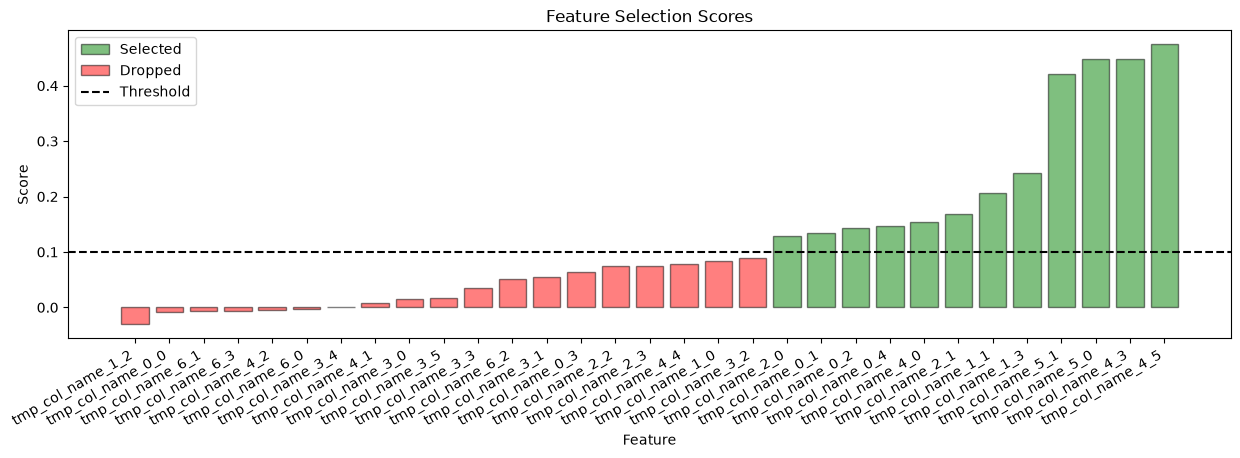

In [45]:
THRESHOLD = 0.1

selected_bar = None
dropped_bar = None
colors = ["red" if score < THRESHOLD else "green" for score in sorted_feat_imp.values()]


fig, ax = plt.subplots(figsize=(15, 4)) 

for i, (feature, score) in enumerate(sorted_feat_imp.items()):
	params = dict(
		x=i,
		height=score,
		edgecolor="black",
		alpha=0.5
	)
	
	if score < THRESHOLD:
		bar = ax.bar(
			color="red",
			**params
		)
		if not dropped_bar:
			dropped_bar = bar[0]
	else:
		bar = ax.bar(
			color="green",
			**params
		)
		if not selected_bar:
			selected_bar = bar[0]

thresh_line = ax.axhline(
	y=0.1,
	color="black",
	linestyle="--"
)

ax.set_xticks(
	ticks=range(len(sorted_feat_imp)),
	labels=list(sorted_feat_imp.keys()),
	rotation=30,
	ha="right"
)

ax.set(
	xlabel="Feature",
	ylabel="Score",
	title="Feature Selection Scores"
)

ax.legend(
	handles=[selected_bar, dropped_bar, thresh_line],
	labels=["Selected", "Dropped", "Threshold"],
	loc="upper left"
)

plt.show()

- The dataset went upto 31 columns after Feature Engineering
- The Feature Selection algorithm selected 13 features out of that